---
title: "L6-09 · Quantum counterfactual questions"
short_title: "Quantum counterfactual questions"
subtitle: "A channel fixes every interventional prediction but not the counterfactual: a counterfactual also needs a dilation, a rule for updating the background on the facts, and a decision about what to hold fixed, and in quantum theory even a fixed dilation leaves the update rule open."
description: "State exactly which extra structure a quantum counterfactual needs beyond the channel, and compute how the answer to one counterfactual query changes with the dilation and with the abduction rule."
tags: [level-6, coursebook]
---

(lesson-l6-09)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 120 minutes  
**Big idea.** A channel fixes every interventional prediction but not the counterfactual: a counterfactual also needs a dilation, a rule for updating the background on the facts, and a decision about what to hold fixed, and in quantum theory even a fixed dilation leaves the update rule open.  
**Before this lesson.** [L4-09](#lesson-l4-09), [L6-02](#lesson-l6-02), [L6-04](#lesson-l6-04)  
**Lab.** [Quantum causal inference](../../labs/11-quantum-causal-inference.ipynb)
:::

## What you will be able to do

- Carry out Pearl's abduction, action and prediction in a structural model, and exhibit two models with the same interventional law and different counterfactual answers.
- Prove that for the completely dephasing qubit channel the counterfactual value $\kappa$ of a fixed query ranges over exactly $[\tfrac12, 1]$ across decompositions of the channel, while the interventional prediction stays $\tfrac12$.
- Compute $\kappa$ for a fixed dilation under different ensemble decompositions of a quantum background and under the hold-fixed and rewind rules, and say which part of the ambiguity is quantum-specific.
- Separate a repeatable interventional prediction from a same-trial counterfactual claim, and state the semantics a quantum counterfactual claim must declare.

## Why this matters

A qubit enters a noisy device prepared in $|+\rangle$, and an $X$ measurement at the output reads $-$. Would the reading have been $+$ had the qubit entered as $|-\rangle$? Everyone who has characterized the device agrees on its channel, so everyone agrees that a fresh $|-\rangle$ gives $+$ with probability $\tfrac12$. Yet the question was not about a fresh trial. It was about this trial, with whatever happened inside the device held fixed. In this lesson you will see equally valid models of the same device answer $1$, $0.875$, $0.75$, $0.625$ and $\tfrac12$.

Classical causal inference already knows that observational and interventional data do not fix counterfactuals; the structural model has to be given [@pearlcausality]. Quantum theory adds a second, independent gap. Even after you fix a reversible model of the device, the hidden background is a quantum system, and there is more than one defensible way to update it on the facts. Research on quantum counterfactuals has not settled on one definition. This lesson does not choose one for you. It makes every choice explicit, proves exactly how much the answer can move, and shows which parts of the ambiguity are classical and which are quantum.

:::{dropdown} Key terms

**Counterfactual query**
: A question of the form: given what actually happened in this trial, what would have happened in the same trial under a different action?

**Abduction**
: The step that updates the background (exogenous) variables on the factual evidence before the action is changed.

**Dilation**
: A description of a channel as a reversible map acting on the system together with a background system in a stated state, followed by discarding the background.

**Ensemble decomposition**
: A way of writing a density operator as a mixture $\sigma = \sum_k q_k |e_k\rangle\langle e_k|$ of pure states; a mixed quantum state has infinitely many.

**Hold-fixed rule**
: The counterfactual rule that keeps the prior background state unchanged (no update on the facts); for any background it returns the interventional prediction.

**Rewind rule**
: A retrodictive rule defined in this lesson: condition the joint system and background state on the factual record, map it back to the input time with the inverse unitary, and keep the background's reduced state.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_09 as _lessonfigs

## Counterfactuals in a classical structural model

Recall the three steps from [L4-09](#lesson-l4-09). In a structural causal model each variable is a function of its parents and of an exogenous background variable. To evaluate a counterfactual given evidence $e$: (1) **abduction**, replace the prior over the background by the posterior given $e$; (2) **action**, replace the equation of the intervened variable by a constant; (3) **prediction**, compute the query in the modified model with the posterior background [@pearlcausality]. The background is what carries the identity of the trial from the factual world to the counterfactual one.

:::{figure} ../../_static/animations/l6_09_three_steps.mp4
:alt: A causal graph with U_X to X, X to Y and U to Y. The evidence X = 1, Y = 1 is entered, the distribution of U collapses to U = 0, the arrow into X is cut and X is set to 0, and the prediction is Y = 0. A second model Y = U' gives the same interventional law and the answer 1.
:width: 100%

Abduction, action, prediction in $Y = X \oplus U$, and a second model with the same interventions and the opposite counterfactual answer.
:::

:::{dropdown} What the animation shows
The graph has nodes $U_X$, $X$, $U$, $Y$ with arrows $U_X \to X$, $X \to Y$ and $U \to Y$, and the model $Y = X \oplus U$ with $U \sim \mathrm{Bern}(\tfrac12)$. Step 1 enters the evidence $X = 1, Y = 1$. Step 2, abduction, rewrites $U = X \oplus Y$ as $U = 1 \oplus 1 = 0$, and a bar chart of $P(U \mid \text{evidence})$ moves from $(0.5, 0.5)$ to $(1, 0)$. Step 3, action, crosses out the arrow $U_X \to X$ and sets $X = 0$. Step 4, prediction, gives $Y_{X=0} = 0 \oplus 0 = 0$. The scene then replaces the model by $Y = U'$, removes the arrow $X \to Y$, and notes that $P(Y = 1 \mid \mathrm{do}(X = x)) = \tfrac12$ in both models. Model 1 answers $P(Y_{X=0} = 1 \mid X{=}1, Y{=}1) = 0$ and Model 2 answers $1$.
:::

$$
P(Y_{x'} = y \mid e) = \sum_{u} P(u \mid e)\,\mathbf{1}\big[f_Y(x', u) = y\big]
$$ (eq-l6-09-pearl)

Equation [](#eq-l6-09-pearl) is the three-step recipe for one equation $Y = f_Y(X, U)$ with $U$ independent of $X$. In the first model $f_Y(x, u) = x \oplus u$, written $Y = X \oplus U$; in the second $f_Y(x, u') = u'$. Both give $P(Y = 1 \mid \mathrm{do}(X = x)) = \tfrac12$ for each $x$, so no experiment that only sets $X$ and records $Y$ can tell them apart. Their counterfactual answers are $0$ and $1$. The counterfactual depends on the functional form and on the background, not only on the interventional law.

:::{important} What carries over to the quantum case
A counterfactual needs three things beyond the interventional law: a model of how background and input produce the output, a rule for updating the background on the facts, and a statement of what is held fixed when the action changes. Each will reappear below, and in quantum theory each becomes a genuine choice.
:::

## One channel, many dilations

In the quantum causal models of [L6-03](#lesson-l6-03), a mechanism is a channel, and the motivation for the quantum Markov condition goes through reversible (unitary) circuits whose background inputs are independent [@allen; @barrett]. A channel does not determine such a circuit. Take the **completely dephasing channel**

$$
\Delta(\rho) = \tfrac12\rho + \tfrac12 Z\rho Z = \begin{pmatrix} \rho_{00} & 0 \\ 0 & \rho_{11} \end{pmatrix}
$$ (eq-l6-09-delta)

and the query from the motivation. **Fact:** the input was $|+\rangle$ and the output $X$ measurement read $-$. **Query:** had the input been $|-\rangle$, what is the probability $\kappa$ that the $X$ measurement would read $+$? The interventional prediction for a fresh trial is $\langle + |\Delta(|-\rangle\langle -|)|+\rangle = \tfrac12$, whatever model of the device is used.

The simplest models give the background a classical label. For any angle $\alpha$, let $\lambda \in \{0, 1\}$ be a fair coin and let the device apply $V_\lambda = R_z(\alpha + \lambda\pi)$, with $R_z(\varphi) = \mathrm{diag}(e^{-i\varphi/2}, e^{i\varphi/2})$. Conjugation by $R_z(\varphi)$ multiplies $\rho_{01}$ by $e^{-i\varphi}$, and $\tfrac12(e^{-i\alpha} + e^{-i(\alpha + \pi)}) = 0$, so the average channel is $\Delta$ for **every** $\alpha$. Abduction is now ordinary Bayes' rule on $\lambda$, and the action keeps $\lambda$.

:::{figure} ../../_static/animations/l6_09_dilation_family.mp4
:alt: The equator of the Bloch sphere with two antipodal branch points whose sizes show posterior weights, and a graph of the counterfactual value falling from 1 to 1/2 as the dilation angle grows, beside a flat dashed line at 1/2 for the intervention.
:width: 100%

The channel never changes, but the counterfactual value $\kappa(\alpha) = 1 - \tfrac{1}{2}\sin^2\alpha$ sweeps from $1$ to $\tfrac12$. The scene ends with the bound $\kappa \ge \tfrac12$.
:::

:::{dropdown} What the animation shows
On the equator of the Bloch sphere, the images of $|+\rangle$ under the two branches $R_z(\alpha)$ and $R_z(\alpha + \pi)$ sit at azimuths $\alpha$ and $\alpha + \pi$. Each branch is drawn as a dot whose size is its posterior weight after the factual $X$ outcome $-$: $\sin^2(\alpha/2)$ and $\cos^2(\alpha/2)$. The text states that $\tfrac12\sum_\lambda V_\lambda \rho V_\lambda^\dagger = \Delta(\rho)$ for every $\alpha$. As $\alpha$ grows from 0 to $\pi/2$ a graph traces $\kappa(\alpha) = 1 - \tfrac{1}{2}\sin^2\alpha$, passing $0.875$ at $\alpha = \pi/6$ and reaching $\tfrac12$ at $\pi/2$, while a dashed line marks the interventional value $\tfrac12$. Finally $\kappa = \sum_k q_k z_k^2 / \sum_k q_k z_k$ is transformed, using $\sum_k q_k z_k = \tfrac12$, into $\kappa = 2\sum_k q_k z_k^2 \ge 2(\sum_k q_k z_k)^2 = \tfrac12$.
:::

:::{prf:theorem} The counterfactual range of complete dephasing
:label: thm-l6-09-range
Let $\Delta = \sum_k q_k \mathcal{E}_k$ be any finite decomposition of the completely dephasing channel into channels $\mathcal{E}_k$ with weights $q_k > 0$. Treat $k$ as a classical background label, abduct it by Bayes' rule on the fact (input $|+\rangle$, $X$ outcome $-$), and hold it fixed while the input is changed to $|-\rangle$. Write $z_k = \langle - |\mathcal{E}_k(|+\rangle\langle +|)|-\rangle$. Then

1. $\kappa = 2\sum_k q_k z_k^2$;
2. $\tfrac12 \le \kappa \le 1$;
3. every value in $[\tfrac12, 1]$ occurs: the two-branch dilation with angle $\alpha \in [0, \pi/2]$ gives $\kappa(\alpha) = 1 - \tfrac{1}{2}\sin^2\alpha$.

The interventional prediction is $\tfrac12$ for every decomposition.
:::

:::{prf:proof}
*Each $\mathcal{E}_k$ keeps the diagonal and scales the off-diagonal entry.* Use the Choi operator $J(\mathcal{E}) = \sum_{ij} |i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ of [L6-02](#lesson-l6-02). Since $\Delta - q_k\mathcal{E}_k$ is completely positive, $0 \le q_k J(\mathcal{E}_k) \le J(\Delta) = |00\rangle\langle 00| + |11\rangle\langle 11|$, so $J(\mathcal{E}_k)$ is supported on $\mathrm{span}\{|00\rangle, |11\rangle\}$. Trace preservation fixes its diagonal there, so $\mathcal{E}_k(|0\rangle\langle 0|) = |0\rangle\langle 0|$, $\mathcal{E}_k(|1\rangle\langle 1|) = |1\rangle\langle 1|$ and $\mathcal{E}_k(|0\rangle\langle 1|) = \mu_k |0\rangle\langle 1|$ with $|\mu_k| \le 1$ by positivity. Averaging gives $\sum_k q_k \mu_k = 0$.

*Likelihoods and counterfactual probabilities coincide.* $\mathcal{E}_k(|\pm\rangle\langle \pm|) = \tfrac12\begin{pmatrix} 1 & \pm\mu_k \\ \pm\bar\mu_k & 1 \end{pmatrix}$, so $z_k = P(- \mid k, |+\rangle) = \tfrac12(1 - \mathrm{Re}\,\mu_k)$ and also $P(+ \mid k, |-\rangle) = \tfrac12(1 - \mathrm{Re}\,\mu_k) = z_k$. Hence $\sum_k q_k z_k = \tfrac12$.

*The value.* The posterior is $q_k z_k / \sum_j q_j z_j = 2q_k z_k$, so $\kappa = \sum_k 2 q_k z_k \cdot z_k$, which is item 1. By Jensen's inequality $\sum_k q_k z_k^2 \ge (\sum_k q_k z_k)^2 = \tfrac14$, and since $0 \le z_k \le 1$, $\sum_k q_k z_k^2 \le \sum_k q_k z_k = \tfrac12$. This is item 2. For the two-branch dilation, $z_0 = \sin^2(\alpha/2)$ and $z_1 = \cos^2(\alpha/2)$, so $\kappa = \sin^4(\alpha/2) + \cos^4(\alpha/2) = 1 - 2\sin^2(\alpha/2)\cos^2(\alpha/2) = 1 - \tfrac{1}{2}\sin^2\alpha$, which is continuous and runs from 1 to $\tfrac12$. The interventional prediction is $\langle +|\Delta(|-\rangle\langle -|)|+\rangle = \tfrac12$. $\square$
:::

$$
\kappa = 2\sum_k q_k z_k^2, \qquad \kappa(\alpha) = 1 - \tfrac{1}{2}\sin^2\alpha
$$ (eq-l6-09-kappa)


In [2]:
_show(_lessonfigs.dilation_explorer())

**Explore.** Drag the dilation angle $\alpha$. The channel is $\Delta$ at every setting. Left: the two branch images of $|+\rangle$, sized by posterior weight. Right: the counterfactual value against the flat interventional value $\tfrac12$.

:::{dropdown} What the figure shows
The first panel shows the Bloch equator with the input $|+\rangle$ and the two branch images at azimuths $\alpha$ and $\alpha + 180^\circ$; marker size is the posterior weight $\sin^2(\alpha/2)$ or $\cos^2(\alpha/2)$. The second panel plots $\kappa(\alpha) = 1 - \tfrac12\sin^2\alpha$ for $\alpha$ from $0^\circ$ to $90^\circ$ with a marker at the chosen angle, and a dashed line at $\tfrac12$ for the interventional prediction. At $0^\circ$ the answer is 1, at $30^\circ$ it is $0.875$, at $45^\circ$ it is $0.75$, at $90^\circ$ it is $\tfrac12$.
:::

:::{prf:remark} This part is not quantum-specific
The theorem is the same phenomenon as the classical pair of models above: one interventional law, many structural models. The background here is a classical coin, and the channel plays the role of $P(Y \mid \mathrm{do}(X))$. What the quantum setting adds is the geometry: the evidence and the query are incompatible measurements on the same qubit, and the range $[\tfrac12, 1]$ is narrower than the classical range $[0, 1]$ of the pair of models because, for this query, the factual likelihood and the counterfactual probability of each component are the same number $z_k$, so the update can only favor components that also favor the outcome $+$.
:::

## The quantum-specific choice: updating a quantum background

Now fix the reversible model completely. Let the background be a qubit $\lambda$ in the state $\sigma = I/2$, and let the device apply the controlled-$Z$ gate $\mathrm{CZ} = I \otimes |0\rangle\langle 0| + Z \otimes |1\rangle\langle 1|$ (system first), then discard $\lambda$. The channel is $\rho \mapsto \tfrac12\rho + \tfrac12 Z\rho Z = \Delta(\rho)$. To abduct, the classical recipe needs the background as a probability distribution over definite values. A mixed quantum state does not supply one: $I/2 = \tfrac12|e_0\rangle\langle e_0| + \tfrac12|e_1\rangle\langle e_1|$ for **every** orthonormal basis, by the unitary freedom of ensembles for density operators [@nielsenchuang]. A probability distribution, by contrast, is a point of a simplex and has exactly one decomposition into point masses.

:::{prf:definition} Ensemble rule
:label: def-l6-09-ensemble
Given a dilation $(U, \sigma)$ and an ensemble decomposition $\sigma = \sum_k q_k |e_k\rangle\langle e_k|$, set $\mathcal{E}_k(\rho) = \operatorname{Tr}_\lambda[U(\rho \otimes |e_k\rangle\langle e_k|)U^\dagger]$. Treat $k$ as the background label: abduct it by Bayes' rule on the fact, hold it fixed, and predict with $\mathcal{E}_k$ under the new input. The decomposition $\sum_k q_k \mathcal{E}_k$ is a decomposition of the channel, so Theorem [](#thm-l6-09-range) applies.
:::

:::{prf:proposition} One dilation, a whole interval of answers
:label: prop-l6-09-ensemble
For $U = \mathrm{CZ}$ and $\sigma = I/2$, take the basis $\{|e_0\rangle, |e_1\rangle\}$ whose first vector has Bloch polar angle $\theta$ (any azimuth). Then $\mathcal{E}_k(\rho) = (1 - z_k)\rho + z_k Z\rho Z$ with $z_0 = \sin^2\tfrac{\theta}{2}$, $z_1 = \cos^2\tfrac{\theta}{2}$, and the ensemble rule gives $\kappa(\theta) = 1 - \tfrac{1}{2}\sin^2\theta$. At $\theta = \pi/3$ this is $0.625$.
:::

:::{prf:proof}
$\mathrm{CZ} = \sum_{j} Z^j \otimes |j\rangle\langle j|$, so $\operatorname{Tr}_\lambda[\mathrm{CZ}(\rho \otimes |e\rangle\langle e|)\mathrm{CZ}^\dagger] = \sum_j |\langle j|e\rangle|^2 Z^j\rho Z^j$. For $|e_0\rangle = \cos\tfrac{\theta}{2}|0\rangle + e^{i\phi}\sin\tfrac{\theta}{2}|1\rangle$ the weight of $Z\rho Z$ is $\sin^2\tfrac{\theta}{2}$, and for the orthogonal vector it is $\cos^2\tfrac{\theta}{2}$; the azimuth $\phi$ drops out. With $q_k = \tfrac12$, item 1 of Theorem [](#thm-l6-09-range) gives $\kappa = \sin^4\tfrac{\theta}{2} + \cos^4\tfrac{\theta}{2} = 1 - \tfrac{1}{2}\sin^2\theta$. $\square$
:::

:::{figure} ../../_static/animations/l6_09_ensemble_choice.mp4
:alt: A Bloch disk with the maximally mixed background at its center and a diameter that rotates away from the vertical axis; its two endpoints are the ensemble members, sized by posterior weight, while a graph traces the counterfactual value from 1 down to 1/2.
:width: 100%

The unitary and the background state $\sigma = I/2$ never change. Only the ensemble used for abduction rotates, and $\kappa(\theta)$ falls from $1$ to $\tfrac12$.
:::

:::{dropdown} What the animation shows
The background state $\sigma = I/2$ is the center of a Bloch disk. A diameter through the center at polar angle $\theta$ marks an ensemble decomposition of $I/2$ into two pure states; their dots are sized by the posterior weights $\sin^2(\theta/2)$ and $\cos^2(\theta/2)$. The text gives $U = \mathrm{CZ}$, $\mathcal{E}_k(\rho) = (1 - z_k)\rho + z_k Z\rho Z$ with $z_0 = \sin^2(\theta/2)$ and $z_1 = \cos^2(\theta/2)$. As $\theta$ goes from 0 to $\pi/2$ a graph traces $\kappa(\theta) = 1 - \tfrac12\sin^2\theta$, marking $0.625$ at $\theta = \pi/3$, above a dashed line at $\tfrac12$. The scene ends by contrasting a classical bit, whose distribution $(\tfrac12, \tfrac12)$ splits into point masses in only one way, with a qubit, where every diameter splits $I/2$ into pure states.
:::

So the quantum-specific ambiguity is this: the same unitary and the same background density operator support every answer in $[\tfrac12, 1]$, depending on which ensemble you treat as the hidden variable. If instead the background is pure, for example $|+\rangle$ with the same CZ (the channel is still $\Delta$, because CZ only reads the diagonal of $\sigma$), the ensemble rule has nothing to update and returns the interventional value $\tfrac12$. Replacing the mixed background by a pure one changes the counterfactual without changing the channel.

:::{prf:remark} The hold-fixed rule
The simplest rule keeps the prior background state $\sigma$ and ignores the facts. The prediction is then $\operatorname{Tr}_\lambda[U(\rho' \otimes \sigma)U^\dagger] = \mathcal{E}(\rho')$, the interventional prediction, for every dilation and every background, pure or mixed; for the lesson's query it is $\tfrac12$. It is a legitimate choice, but nothing about the particular trial is carried over, so it is a counterfactual only in name.
:::

:::{prf:definition} Rewind rule (defined in this lesson)
:label: def-l6-09-rewind
Given a dilation $(U, \sigma)$, factual input $\rho$ and a factual output projector $\Pi$ observed with probability $p > 0$, form the conditioned joint state at the input time, $\omega = U^\dagger(\Pi \otimes I)U(\rho \otimes \sigma)U^\dagger(\Pi \otimes I)U / p$, keep the background $\sigma' = \operatorname{Tr}_S\,\omega$, discard its correlations with the system, and predict with $(U, \sigma')$ under the new input.
:::

:::{prf:proposition} Rewinding is Bayes for classically controlled dilations
:label: prop-l6-09-rewind
If $U = \sum_k V_k \otimes |k\rangle\langle k|$ and $\sigma = \sum_k p_k |k\rangle\langle k|$, then $\sigma' = \sum_k p(k \mid \Pi) |k\rangle\langle k|$ with $p(k \mid \Pi) = p_k \operatorname{Tr}[\Pi V_k \rho V_k^\dagger] / p$, so the rewind rule reproduces Pearl's abduction.
:::

:::{prf:proof}
$U^\dagger(\Pi \otimes I)U = \sum_k V_k^\dagger \Pi V_k \otimes |k\rangle\langle k|$. Because $\sigma$ is diagonal in the same basis, the cross terms $k \ne l$ vanish and $\omega = \sum_k p_k (V_k^\dagger\Pi V_k)\rho(V_k^\dagger\Pi V_k) \otimes |k\rangle\langle k| / p$. Tracing out the system and using $\Pi^2 = \Pi$ gives $\operatorname{Tr}[V_k^\dagger \Pi V_k \rho] = \operatorname{Tr}[\Pi V_k\rho V_k^\dagger]$. $\square$
:::

:::{figure} ../../_static/animations/l6_09_pure_rewind.mp4
:alt: A derivation for the CNOT dilation with environment |0>: the entangled output, the projection on the factual outcome, and the rewound state |+>|->, followed by a Bloch disk showing the prior |0> and the rewound |-> at right angles, and the two answers 1/2 and 1.
:width: 100%

The pure dilation $\mathrm{CNOT}_{S \to E}$ with $|0\rangle_E$: holding the background fixed gives $\tfrac12$; rewinding gives the background $|-\rangle_E$, which lies outside the prior's support, and the answer 1.
:::

:::{dropdown} What the animation shows
The setup is $U = \mathrm{CNOT}_{S \to E}$ with background $|0\rangle_E$. The first line computes $\mathrm{CNOT}\,|+\rangle|0\rangle = \tfrac{1}{\sqrt2}(|00\rangle + |11\rangle)$. It transforms into the projection $(|-\rangle\langle -| \otimes I)\tfrac{1}{\sqrt2}(|00\rangle + |11\rangle) = \tfrac{1}{\sqrt2}|-\rangle|-\rangle$, so the factual outcome has probability $0.5$. It then transforms into the rewind $\mathrm{CNOT}^\dagger|-\rangle|-\rangle = |+\rangle|-\rangle$, the state at the input time. A Bloch disk shows the prior background $|0\rangle$ as an arrow to the north pole and the rewound background $|-\rangle$ as an arrow to the left, labeled as outside the prior's support. The results: holding $|0\rangle_E$ fixed gives $\kappa = \tfrac12$; rewinding to $|-\rangle_E$ gives $\kappa = 1$.
:::

The CNOT dilation $\mathrm{CNOT}_{S \to E}(\rho \otimes |0\rangle\langle 0|)\mathrm{CNOT}^\dagger$ also has channel $\Delta$: it copies the $Z$ value into the environment. Rewinding the factual record gives the joint input-time state $|+\rangle|-\rangle$, so $\sigma' = |-\rangle\langle -|$. Classical abduction never leaves the support of the prior; here the prior is $|0\rangle\langle 0|$ and the updated background has weight $\tfrac12$ on $|1\rangle$. Whether such an update is acceptable is a choice about semantics, not something the channel or the dilation decides.


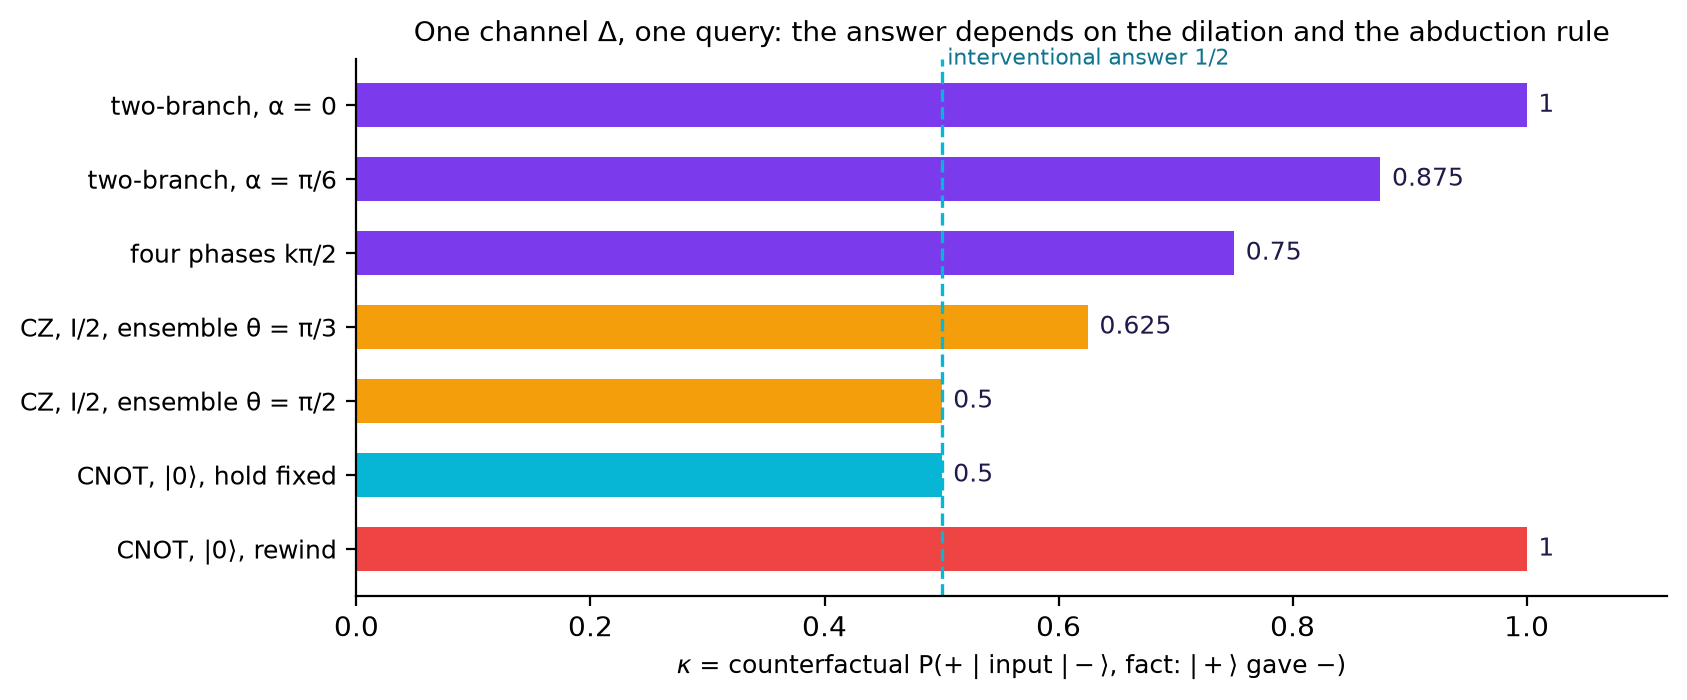

In [3]:
_show_mpl(_lessonfigs.answers_by_choice())

*Seven answers to one query about one channel. Violet: classical labels with different decompositions (Theorem [](#thm-l6-09-range)). Orange: one dilation with different background ensembles (Proposition [](#prop-l6-09-ensemble)). Cyan and red: one pure dilation under the hold-fixed and rewind rules.*

## What a quantum counterfactual must declare

```{mermaid}
graph LR
  F[Factual record] --> A[Abduction rule]
  C[Channel] --> D[Dilation and background]
  D --> A
  A --> H[What is held fixed]
  H --> P[Prediction]
  Q[Counterfactual action] --> P
  C --> I[Interventional prediction]
  Q --> I
```

*The channel alone feeds the interventional prediction. A counterfactual also passes through a dilation, an abduction rule and a choice of what to hold fixed; each box is a declared modeling choice.*

The examples suggest a checklist. A quantum counterfactual claim should state: the causal structure and the systems at each node; the dilation, or more generally the class of background models allowed; the abduction rule, including how a quantum background is turned into something that can be conditioned; what is held fixed during the action (a classical label, a quantum state, or correlations as well); and the factual record, including which incompatible measurement was actually made. Published proposals make different commitments at several of these points, and this lesson does not rank them. For example, Suresh, Frembs and Cavalcanti extend Pearl's three steps to quantum causal models, with abduction done by classical Bayesian inference on the outcomes of instruments at exogenous nodes [@suresh2023]. Leifer and Spekkens develop quantum conditional states and a quantum analogue of Bayesian inference [@leifer]; the Petz recovery map, which also underlies the recovery results of Junge and coauthors [@petz], gives another quantum analogue of Bayesian inversion, and it reduces to Bayes' rule when every operator involved is diagonal in one basis (the first challenge exercise). Either could be used to define an abduction step, and they need not agree with the two rules above.

:::{warning} Do not invent joint records of incompatible measurements
Prepare $|+\rangle$ and measure $Z$, obtaining 0. A fresh trial with an $X$ measurement gives $+$ with certainty. That is a prediction about a different procedure. It does not mean that the recorded $Z$ trial also had an $X$ value. Nothing in the quantum formalism supplies a joint record of outcomes of incompatible measurements, so a counterfactual that quietly assumes one has added a hidden-variable model without saying so.
:::

Often the question that matters operationally is interventional: what will happen if we prepare $|-\rangle$ next time? That question has the answer $\tfrac12$, determined by the channel and testable by repetition. A same-trial counterfactual is a different quantity; it can be useful for explanation, attribution or fairness, but only after its semantics are fixed, and no experiment on the channel alone can confirm one answer over another.

## Compute it

Every number in this lesson, recomputed: the two-branch family and the four-phase dilation (all checked to have the Choi operator of $\Delta$), one CZ dilation under three ensembles, the pure CNOT dilation under the hold-fixed and rewind rules, the classical pair of models, and a check that the Petz map of a classical channel is Bayes' rule.


In [4]:
import math
import itertools
import numpy as np
from qcai import science as s

PLUS = np.array([1, 1]) / math.sqrt(2)
MINUS = np.array([1, -1]) / math.sqrt(2)
proj = lambda v: np.outer(v, np.conj(v))
rz = lambda a: np.diag([np.exp(-1j * a / 2), np.exp(1j * a / 2)])
J_DELTA = s.choi(s.dephasing_kraus(1.0))      # complete Z dephasing; Choi convention of qcai.science

def mixture_choi(channels, q):
    return sum(qk * s.choi(K) for qk, K in zip(q, channels))

def bayes_counterfactual(channels, q):
    """Fact: input |+>, X outcome -.  Query: had the input been |->, P(X outcome +)?  Label k held fixed."""
    q = np.asarray(q, float)
    lik = np.array([np.real(np.trace(proj(MINUS) @ s.apply_kraus(proj(PLUS), K))) for K in channels])
    post = q * lik / np.sum(q * lik)
    cf = np.array([np.real(np.trace(proj(PLUS) @ s.apply_kraus(proj(MINUS), K))) for K in channels])
    return float(post @ cf), post

# 1. two-branch dilations R_z(alpha), R_z(alpha + pi): same channel, different answers
for deg in (0, 30, 45, 60, 90):
    a = math.radians(deg)
    chans = [[rz(a)], [rz(a + math.pi)]]
    assert np.allclose(mixture_choi(chans, [0.5, 0.5]), J_DELTA)
    k, post = bayes_counterfactual(chans, [0.5, 0.5])
    assert abs(k - (1 - 0.5 * math.sin(a) ** 2)) < 1e-12
    print(f"alpha = {deg:2d} deg  posterior {np.round(post, 4)}  kappa = {k:.4f}")

# 2. four phase rotations k*pi/2
chans4 = [[rz(k * math.pi / 2)] for k in range(4)]
assert np.allclose(mixture_choi(chans4, [0.25] * 4), J_DELTA)
print("four phases: kappa =", round(bayes_counterfactual(chans4, [0.25] * 4)[0], 4))

# 3. one dilation (CZ, background I/2), different ensemble decompositions of the background
CZ = np.diag([1, 1, 1, -1]).astype(complex)            # order: system (x) background
def kraus_from_dilation(U, e):
    """Kraus operators K_j = (I (x) <j|) U (I (x) |e>) of rho -> Tr_bg[U (rho (x) |e><e|) U^dag]."""
    T = U.reshape(2, 2, 2, 2)                          # indices [s_out, bg_out, s_in, bg_in]
    return [np.einsum("acd,d->ac", T[:, j], e) for j in range(2)]
for deg in (0, 60, 90):
    t = math.radians(deg)
    e0 = np.array([math.cos(t / 2), math.sin(t / 2)], complex)
    e1 = np.array([-math.sin(t / 2), math.cos(t / 2)], complex)
    assert np.allclose(0.5 * proj(e0) + 0.5 * proj(e1), np.eye(2) / 2)     # both decompose sigma = I/2
    chans = [kraus_from_dilation(CZ, e0), kraus_from_dilation(CZ, e1)]
    assert all(s.is_cptp(K) for K in chans) and np.allclose(mixture_choi(chans, [0.5, 0.5]), J_DELTA)
    k = bayes_counterfactual(chans, [0.5, 0.5])[0]
    assert abs(k - (1 - 0.5 * math.sin(t) ** 2)) < 1e-12
    print(f"CZ, I/2, ensemble at theta = {deg:2d} deg: kappa = {k:.4f}")

# 4. pure dilation CNOT with background |0>: hold fixed versus rewind
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
K_cnot = kraus_from_dilation(CNOT, np.array([1, 0], complex))
assert np.allclose(s.choi(K_cnot), J_DELTA)
def p_plus_out(bg):
    out = CNOT @ np.kron(proj(MINUS), bg) @ CNOT.conj().T
    return float(np.real(np.trace(s.partial_trace(out, 0) @ proj(PLUS))))
post = np.kron(proj(MINUS), np.eye(2)) @ CNOT @ np.kron(PLUS, [1, 0])
p_fact = float(np.vdot(post, post).real)
rewound = CNOT.conj().T @ post / math.sqrt(p_fact)
bg_post = s.partial_trace(proj(rewound), 1)
print("P(fact) =", round(p_fact, 4), " rewound joint state equals |+>|->:", np.allclose(rewound, np.kron(PLUS, MINUS)))
print("weight of the rewound background outside the prior support span{|0>}:", round(np.real(bg_post[1, 1]), 4))
print("hold |0> fixed: kappa =", round(p_plus_out(proj(np.array([1, 0]))), 4), "  rewind: kappa =", round(p_plus_out(bg_post), 4))

# 5. the classical pair of models: same interventions, opposite counterfactuals
for name, f in (("Y = X xor U", lambda x, u: x ^ u), ("Y = U'", lambda x, u: u)):
    do = [float(np.mean([f(x, u) for u in (0, 1)])) for x in (0, 1)]
    us = [u for u in (0, 1) if f(1, u) == 1]              # abduction on X = 1, Y = 1 (uniform prior)
    print(f"{name:12s} P(Y=1|do(x)) = {do}  P(Y_(X=0) = 1 | X=1, Y=1) = {float(np.mean([f(0, u) for u in us]))}")

# 6. the Petz map of a classical channel is Bayes' rule
g = np.random.default_rng(9)
p = g.dirichlet(np.ones(3)); W = g.dirichlet(np.ones(2), size=3)       # W[x, y] = P(y | x)
kraus = [math.sqrt(W[x, y]) * np.outer(np.eye(2)[y], np.eye(3)[x]) for x in range(3) for y in range(2)]
N = lambda r: sum(K @ r @ K.T for K in kraus)                           # Schrodinger picture
Nadj = lambda a: sum(K.T @ a @ K for K in kraus)                        # Heisenberg picture
sig = np.diag(p); out_inv_sqrt = np.diag(np.diag(N(sig)) ** -0.5)
for y in range(2):
    petz = np.sqrt(sig) @ Nadj(out_inv_sqrt @ np.diag(np.eye(2)[y]) @ out_inv_sqrt) @ np.sqrt(sig)
    assert np.allclose(petz, np.diag(p * W[:, y] / (p @ W[:, y])))      # Bayes posterior P(x | y)
print("Petz map on a classical channel = Bayes posterior: checked")

alpha =  0 deg  posterior [0. 1.]  kappa = 1.0000
alpha = 30 deg  posterior [0.067 0.933]  kappa = 0.8750
alpha = 45 deg  posterior [0.1464 0.8536]  kappa = 0.7500
alpha = 60 deg  posterior [0.25 0.75]  kappa = 0.6250
alpha = 90 deg  posterior [0.5 0.5]  kappa = 0.5000
four phases: kappa = 0.75
CZ, I/2, ensemble at theta =  0 deg: kappa = 1.0000
CZ, I/2, ensemble at theta = 60 deg: kappa = 0.6250
CZ, I/2, ensemble at theta = 90 deg: kappa = 0.5000
P(fact) = 0.5  rewound joint state equals |+>|->: True
weight of the rewound background outside the prior support span{|0>}: 0.5
hold |0> fixed: kappa = 0.5   rewind: kappa = 1.0
Y = X xor U  P(Y=1|do(x)) = [0.5, 0.5]  P(Y_(X=0) = 1 | X=1, Y=1) = 0.0
Y = U'       P(Y=1|do(x)) = [0.5, 0.5]  P(Y_(X=0) = 1 | X=1, Y=1) = 1.0
Petz map on a classical channel = Bayes posterior: checked


:::{prf:remark} Reading the output
The four-phase dilation with angles $k\pi/2$ gives $0.75$, inside the interval of Theorem [](#thm-l6-09-range). The CZ dilation with $\sigma = I/2$ gives $1$, $0.625$ and $0.5$ for ensembles at $\theta = 0^\circ, 60^\circ, 90^\circ$. The rewound background has weight $0.5$ outside the support of $|0\rangle$. All of these devices have the same Choi operator, so no tomography of the channel can distinguish them.
:::

## Worked example

:::{admonition} The two-branch dilation at a quarter turn
:class: tip

Use the dilation $V_0 = R_z(\pi/4)$, $V_1 = R_z(5\pi/4)$ with a fair coin. Check that the channel is $\Delta$, then compute the posterior on the coin after the fact (input $|+\rangle$, $X$ outcome $-$) and the counterfactual value $\kappa$ for the input $|-\rangle$. Compare with the interventional prediction.

1. Channel: conjugation by $R_z(\varphi)$ multiplies $\rho_{01}$ by $e^{-i\varphi}$, and $\tfrac12(e^{-i\pi/4} + e^{-i5\pi/4}) = \tfrac12 e^{-i\pi/4}(1 - 1) = 0$, while the diagonal is unchanged. So the average channel is $\Delta$.
2. Likelihoods: $R_z(\varphi)|+\rangle$ has Bloch azimuth $\varphi$, so $P(- \mid \lambda) = \sin^2(\varphi_\lambda/2)$: $\sin^2(\pi/8) = (1 - \cos\tfrac{\pi}{4})/2 \approx 0.1464$ and $\sin^2(5\pi/8) = \cos^2(\pi/8) \approx 0.8536$. With a fair prior the posterior equals the likelihoods: $(0.1464, 0.8536)$.
3. Counterfactual: for a diagonal unitary $|\langle + |V|-\rangle|^2 = |\langle - |V|+\rangle|^2$, so $P(+ \mid \lambda, |-\rangle)$ is again $(0.1464, 0.8536)$, and $\kappa = 0.1464^2 + 0.8536^2 \approx 0.0214 + 0.7286 = 0.75$.
4. Check against [](#eq-l6-09-kappa): $1 - \tfrac12\sin^2(\pi/4) = 1 - \tfrac14 = 0.75$. The interventional prediction is $\tfrac12$.

**Result.** $\kappa = 0.75$ for this dilation, against the interventional $\tfrac12$. The factual record makes the branch that maps $|+\rangle$ near $|-\rangle$ more likely, and that branch also maps $|-\rangle$ near $|+\rangle$.
:::

## Exercises

**1. (Core)** For the two-branch dilation with $\alpha = \pi/3$, compute the posterior weights after the fact and the counterfactual value $\kappa$.

:::{dropdown} Solution
The weights are $\sin^2(\pi/6) = \tfrac14$ and $\cos^2(\pi/6) = \tfrac34$. Then $\kappa = (\tfrac14)^2 + (\tfrac34)^2 = \tfrac{1}{16} + \tfrac{9}{16} = 0.625$, which equals $1 - \tfrac12\sin^2(\pi/3) = 1 - \tfrac38$.
:::

**2. (Core)** In the classical pair of models $Y = X \oplus U$ and $Y = U'$ (fair background bits), compute $P(Y_{X=0} = 1 \mid X = 1, Y = 0)$ in each model.

:::{dropdown} Solution
Model 1: abduction gives $U = X \oplus Y = 1$, so $Y_{X=0} = 0 \oplus 1 = 1$ and the probability is 1. Model 2: abduction gives $U' = Y = 0$, so $Y_{X=0} = 0$ and the probability is 0. The interventional laws agree, the counterfactuals are opposite.
:::

**3. (Stretch)** Show that the CZ gate with a pure background $|+\rangle$ implements $\Delta$, and that the ensemble rule then gives $\kappa = \tfrac12$.

:::{dropdown} Solution
$\operatorname{Tr}_\lambda[\mathrm{CZ}(\rho \otimes |+\rangle\langle +|)\mathrm{CZ}^\dagger] = \sum_j |\langle j|+\rangle|^2 Z^j\rho Z^j = \tfrac12\rho + \tfrac12 Z\rho Z = \Delta(\rho)$. A pure state is an extreme point of the state space, so its only ensemble decomposition is itself. There is one label, the posterior equals the prior, and $\kappa = \langle + |\Delta(|-\rangle\langle -|)|+\rangle = \tfrac12$.
:::

**4. (Stretch)** The pure dilations $(\mathrm{CNOT}_{S \to E}, |0\rangle)$ and $(\mathrm{CZ}, |+\rangle)$ are related by a Hadamard on the environment. Compute the rewind-rule background and $\kappa$ for $(\mathrm{CZ}, |+\rangle)$ and compare with the CNOT result.

:::{dropdown} Solution
$\mathrm{CZ}^\dagger(\Pi_- \otimes I)\mathrm{CZ} = \Pi_- \otimes |0\rangle\langle 0| + \Pi_+ \otimes |1\rangle\langle 1|$, because $Z\Pi_- Z = \Pi_+$. Applied to $|+\rangle|+\rangle$ it gives $\tfrac{1}{\sqrt2}|+\rangle|1\rangle$, so $p = \tfrac12$ and $\sigma' = |1\rangle\langle 1|$. With background $|1\rangle$ the device applies $Z$, which maps $|-\rangle$ to $|+\rangle$, so $\kappa = 1$. For CNOT the rewound background was $|-\rangle = H|1\rangle$ and $\kappa = 1$ too: the rewind rule transforms covariantly with the environment unitary, and the hold-fixed rule gives $\tfrac12$ in both.
:::

**5. (Challenge)** Let $\sigma = \mathrm{diag}(p_x)$ be a classical prior and let $\mathcal{N}$ be the classical channel with transition matrix $P(y \mid x)$, acting on diagonal states. The Petz map is $\mathcal{R}(\tau) = \sigma^{1/2}\mathcal{N}^\dagger\big(\mathcal{N}(\sigma)^{-1/2}\tau\,\mathcal{N}(\sigma)^{-1/2}\big)\sigma^{1/2}$. Show that $\mathcal{R}(|y\rangle\langle y|)$ is the Bayes posterior $\sum_x P(x \mid y)|x\rangle\langle x|$.

:::{dropdown} Solution
$\mathcal{N}(\sigma) = \mathrm{diag}(q_y)$ with $q_y = \sum_x P(y \mid x)p_x$, so $\mathcal{N}(\sigma)^{-1/2}|y\rangle\langle y|\mathcal{N}(\sigma)^{-1/2} = q_y^{-1}|y\rangle\langle y|$. The adjoint (Heisenberg) map of a classical channel is $\mathcal{N}^\dagger(|y\rangle\langle y|) = \sum_x P(y \mid x)|x\rangle\langle x|$. Conjugating by $\sigma^{1/2}$ multiplies the $x$ entry by $p_x$: $\mathcal{R}(|y\rangle\langle y|) = \sum_x p_x P(y \mid x)/q_y\,|x\rangle\langle x| = \sum_x P(x \mid y)|x\rangle\langle x|$, which is Bayes' rule.
:::

**6. (Challenge)** Characterize the decompositions $\Delta = \sum_k q_k\mathcal{E}_k$ for which $\kappa = 1$ and those for which $\kappa = \tfrac12$.

:::{dropdown} Solution
By Theorem [](#thm-l6-09-range), $\kappa = 2\sum_k q_k z_k^2$ with $\sum_k q_k z_k = \tfrac12$ and $z_k \in [0, 1]$. $\kappa = 1$ iff $\sum_k q_k z_k^2 = \sum_k q_k z_k$, i.e. $z_k(1 - z_k) = 0$ for every $k$: each $\mathcal{E}_k$ has $\mathrm{Re}\,\mu_k = \pm 1$, hence $\mu_k = \pm 1$, so each component is the identity or conjugation by $Z$ (the two-branch dilation with $\alpha = 0$ up to relabeling). $\kappa = \tfrac12$ iff Jensen's inequality is tight, i.e. $z_k = \tfrac12$ for all $k$: every component has $\mathrm{Re}\,\mu_k = 0$, for example $R_z(\pm\pi/2)$, or the trivial decomposition $\mathcal{E}_1 = \Delta$.
:::

## Check your understanding

**1. For the two-branch dilation $R_z(\alpha)$, $R_z(\alpha + \pi)$ of complete dephasing with $\alpha = \pi/2$, what is the counterfactual value $\kappa$ of the lesson's query?**

- **A.** $0$
- **B.** $\tfrac12$
- **C.** $0.75$
- **D.** $1$

:::{dropdown} Show the answer
**B. $\tfrac12$**

$\kappa(\alpha) = 1 - \tfrac12\sin^2\alpha = 1 - \tfrac12 = \tfrac12$. Both branches have likelihood $\tfrac12$, so the factual record carries no information about the label.
:::

**2. Which of these is the same for every dilation of a given channel?**

- **A.** The dimension of the background
- **B.** The posterior over the background
- **C.** Every interventional prediction
- **D.** Every counterfactual value

:::{dropdown} Show the answer
**C. Every interventional prediction**

Interventional predictions depend only on the channel. Counterfactuals, posteriors and background dimensions all vary between dilations, as Theorem [](#thm-l6-09-range) shows.
:::

**3. Why does fixing the unitary and the background density operator still not fix the abduction step?**

- **A.** Quantum states cannot be conditioned on data
- **B.** A mixed quantum state has many ensemble decompositions into pure states
- **C.** The Born rule forbids Bayesian updating
- **D.** The channel changes when the background is updated

:::{dropdown} Show the answer
**B. A mixed quantum state has many ensemble decompositions into pure states**

Classical abduction conditions a distribution over definite background values, and a distribution decomposes into point masses in one way. $I/2$ decomposes into any orthonormal basis, and Proposition [](#prop-l6-09-ensemble) shows the answer depends on that choice.
:::

**4. In the model $Y = X \oplus U$ with a fair background bit, you observe $X = 0$ and $Y = 1$. What would $Y$ have been had $X$ been 1?** *(Review of [L4-09](#lesson-l4-09))*

- **A.** 1
- **B.** 0
- **C.** $\tfrac12$

:::{dropdown} Show the answer
**B. 0**

Abduction gives $U = X \oplus Y = 1$. Action sets $X = 1$. Prediction gives $Y = 1 \oplus 1 = 0$.
:::

## Common misconceptions

- **"A quantum counterfactual is just the probability for a fresh trial with the new input."** That is the interventional prediction, fixed by the channel ($\tfrac12$ in the lesson's example). A counterfactual conditions on what happened in this trial, and its value depends on the dilation and on the abduction rule.
- **"If two devices have the same channel, they must give the same counterfactual answers."** Theorem [](#thm-l6-09-range) gives devices with identical Choi operators and counterfactual values anywhere in $[\tfrac12, 1]$. The same is true classically for structural models with one interventional law.
- **"Once the unitary dilation is fixed, the quantum counterfactual is fixed."** A quantum background must still be turned into something that can be conditioned. For one fixed dilation, the ensemble rule gives any value in $[\tfrac12, 1]$ and the hold-fixed and rewind rules can disagree ($\tfrac12$ against $1$).
- **"There is an agreed definition of quantum counterfactuals that this lesson leaves out."** Several proposals exist, for example [@suresh2023], and they make different commitments. The lesson's rules are minimal illustrations, chosen to make each commitment visible, not a summary of any one proposal.

:::{caution} Scope and limits
This lesson uses one channel (complete $Z$ dephasing), one query and finite decompositions; the theorem is exact only for that setting. The ensemble, hold-fixed and rewind rules are illustrations defined here, not definitions taken from the literature, and the lesson does not claim that any of them is correct. Conventions: system before background in tensor products, $R_z(\varphi) = \mathrm{diag}(e^{-i\varphi/2}, e^{i\varphi/2})$, the Choi operator $J(\mathcal{E}) = \sum_{ij}|i\rangle\langle j| \otimes \mathcal{E}(|i\rangle\langle j|)$ of `qcai.science.choi`. Everything is a classical simulation of textbook formulas; no counterfactual can be confirmed by experiments on the channel alone.
:::

:::{seealso} Where this leads
The same separation of interventional and counterfactual content returns in [L6-10](#lesson-l6-10), where an experiment is designed to test only what the channel and the process determine. In Level 7, attribution and explanation claims for quantum models need the semantics fixed here before they can be evaluated.
:::

:::{dropdown} For instructors

**Why this lesson.** Graduate students often meet quantum counterfactuals through informal paradoxes. Working one query through classical labels, background ensembles and two update rules shows precisely where the extra structure enters, and the theorem gives a provable statement about how much it matters [@pearlcausality; @allen; @barrett].

**Teaching notes.**

- Begin with the classical pair of models and ask students to design an intervention that tells them apart; they cannot, and that is the point of the lesson.
- Have students predict $\kappa$ for $\alpha = 0$ and $\alpha = \pi/2$ before showing the interactive; most predict that the channel decides, and the sweep corrects them.
- Spend time on the remark that the first gap is classical. The quantum-specific claim is Proposition [](#prop-l6-09-ensemble): one unitary, one background state, many answers.
- When discussing the rewind rule, ask whether a background update outside the prior's support should be allowed; there is no single right answer, and arguing both sides is the exercise.

**Assessment.** The core exercises test the mechanics of abduction; the stretch exercises test whether students can compute with dilations; the challenge exercises test the proof technique of the theorem and the classical limit of the Petz map.

**Going further.** Ask students to define a Petz-based abduction step for the CZ dilation and compute its answer for the lesson's query, then compare it with the ensemble and rewind rules. Leifer and Spekkens give the background on quantum conditional states [@leifer], and Junge and coauthors discuss the Petz recovery map [@petz].

:::

## References

This lesson draws on [@pearlcausality; @nielsenchuang; @allen; @barrett; @leifer; @petz; @watrous; @suresh2023].

**Further reading.**

- [@pearlcausality]: Chapter 7 develops structural counterfactuals and the abduction, action, prediction procedure.
- [@watrous]: Chapter 2 treats Stinespring and Kraus representations of channels and their non-uniqueness in full generality.
- [@leifer]: Quantum conditional states and a causally neutral formulation of quantum Bayesian inference.

**Next:** [L6-10 · Design a quantum causal experiment](#lesson-l6-10)
